# Product Recommendation Prediction

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold
import optuna
import re
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import make_scorer
from scipy.stats import spearmanr
from scipy.sparse import hstack, csr_matrix
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
import sentencepiece
import os
from scipy.stats import rankdata

D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Завантаження тренувального датасету:

In [4]:
file_name = "train.csv"
df_review_data = pd.read_csv(file_name)
df_review_data

,Id,Age,Review_Title,Review,Pos_Feedback_Cnt,Division,Department,Product_Category,Rating,Recommended
0,17274,34,Cute fall/holiday top,Love this top! the quality is magnificent and ...,1,General,Tops,Blouses,5,1
1,5921,35,NaN,NaN,0,General,Tops,Blouses,5,1
2,16479,40,Disappointed,"Sleeves were tight, was difficult to put on ?....",15,General,Tops,Blouses,2,0
3,1925,28,Gorgeous detailing,I never write reviews but this clothe is so fa...,3,General Petite,Clothes,Clothes,5,1
4,5691,39,Cute and comfortable tee!,Love this tshirt! casual but can be clotheed u...,0,General,Tops,Knits,5,1
...,...,...,...,...,...,...,...,...,...,...
14086,13641,38,Too flowy,The pattern and fabric on this clothe are very...,0,General,Clothes,Clothes,3,0
14087,2245,44,"Soft, snuggly and cute","Like the previous reviewer stated, it's more l...",2,General,Tops,Sweaters,5,1
14088,16929,44,Gorgeous!,This sweater is so lovely.. i like the fact th...,1,General Petite,Tops,Sweaters,5,1
14089,7362,54,Really versatile!,"I just love this top, it has a flattering cut,...",1,General Petite,Tops,Blouses,5,1


## Виконання Exploratory Data Analysis (EDA) для датасету

In [5]:
df_review_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14091 entries, 0 to 14090
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Id                14091 non-null  int64 
 1   Age               14091 non-null  int64 
 2   Review_Title      11732 non-null  object
 3   Review            13588 non-null  object
 4   Pos_Feedback_Cnt  14091 non-null  int64 
 5   Division          14080 non-null  object
 6   Department        14080 non-null  object
 7   Product_Category  14080 non-null  object
 8   Rating            14091 non-null  int64 
 9   Recommended       14091 non-null  int64 
dtypes: int64(5), object(5)
memory usage: 1.1+ MB


In [6]:
df_review_data.isnull().sum()

Id                     0
Age                    0
Review_Title        2359
Review               503
Pos_Feedback_Cnt       0
Division              11
Department            11
Product_Category      11
Rating                 0
Recommended            0
dtype: int64

In [7]:
df_review_data.describe()

,Id,Age,Pos_Feedback_Cnt,Rating,Recommended
count,14091.000000,14091.000000,14091.000000,14091.000000,14091.000000
mean,11713.941736,43.093677,2.465474,4.197786,0.822511
std,6768.152493,12.176401,5.519936,1.109792,0.382096
min,0.000000,18.000000,0.000000,1.000000,0.000000
25%,5860.000000,34.000000,0.000000,4.000000,1.000000
50%,11693.000000,41.000000,1.000000,5.000000,1.000000
75%,17555.500000,51.000000,3.000000,5.000000,1.000000
max,23485.000000,94.000000,122.000000,5.000000,1.000000


Видаляємо неінформативну ознаку Id (всі значення унікальні):

In [8]:
df_review_data = df_review_data.drop(columns=["Id"], errors="ignore")
df_review_data

,Age,Review_Title,Review,Pos_Feedback_Cnt,Division,Department,Product_Category,Rating,Recommended
0,34,Cute fall/holiday top,Love this top! the quality is magnificent and ...,1,General,Tops,Blouses,5,1
1,35,NaN,NaN,0,General,Tops,Blouses,5,1
2,40,Disappointed,"Sleeves were tight, was difficult to put on ?....",15,General,Tops,Blouses,2,0
3,28,Gorgeous detailing,I never write reviews but this clothe is so fa...,3,General Petite,Clothes,Clothes,5,1
4,39,Cute and comfortable tee!,Love this tshirt! casual but can be clotheed u...,0,General,Tops,Knits,5,1
...,...,...,...,...,...,...,...,...,...
14086,38,Too flowy,The pattern and fabric on this clothe are very...,0,General,Clothes,Clothes,3,0
14087,44,"Soft, snuggly and cute","Like the previous reviewer stated, it's more l...",2,General,Tops,Sweaters,5,1
14088,44,Gorgeous!,This sweater is so lovely.. i like the fact th...,1,General Petite,Tops,Sweaters,5,1
14089,54,Really versatile!,"I just love this top, it has a flattering cut,...",1,General Petite,Tops,Blouses,5,1


## Аналіз цільових змінних

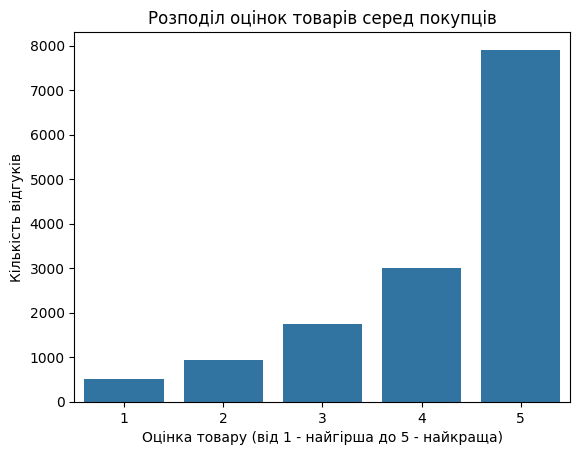

In [9]:
sns.countplot(data=df_review_data, x="Rating")
plt.title("Розподіл оцінок товарів серед покупців")
plt.xlabel("Оцінка товару (від 1 - найгірша до 5 - найкраща)")
plt.ylabel("Кількість відгуків")
plt.show()

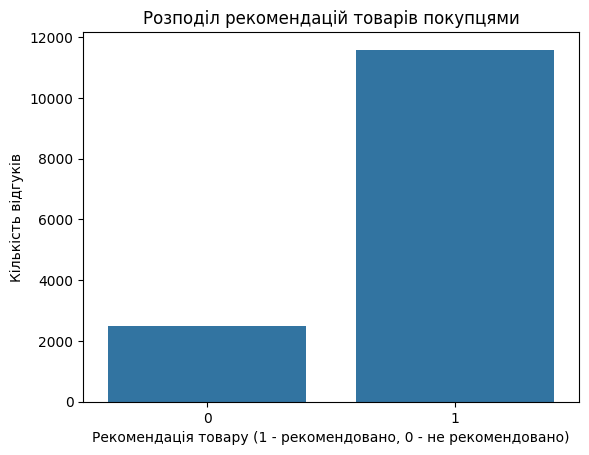

In [10]:
sns.countplot(data=df_review_data, x="Recommended")
plt.title("Розподіл рекомендацій товарів покупцями")
plt.xlabel("Рекомендація товару (1 - рекомендовано, 0 - не рекомендовано)")
plt.ylabel("Кількість відгуків")
plt.show()

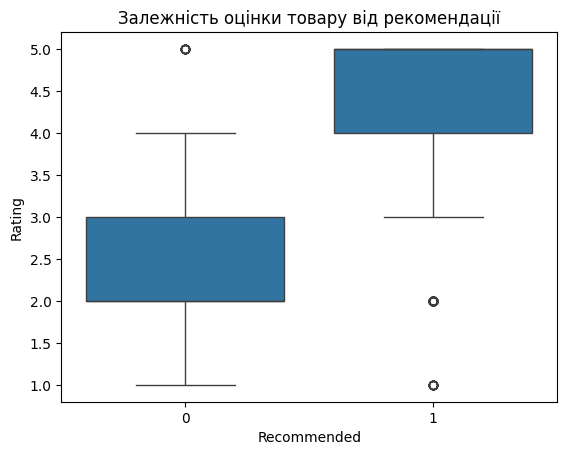

In [11]:
sns.boxplot(data=df_review_data, x="Recommended", y="Rating")
plt.title("Залежність оцінки товару від рекомендації")
plt.show()

## Аналіз числових ознак

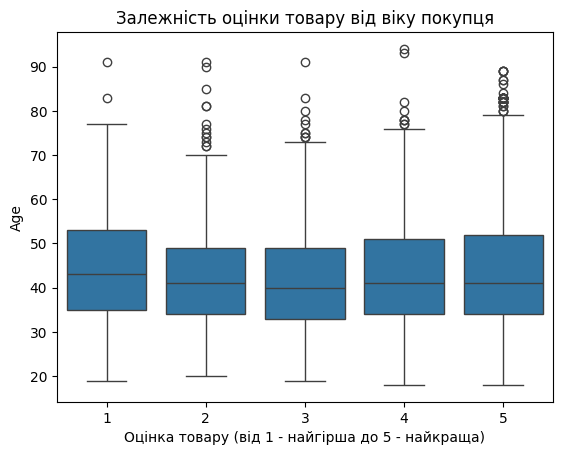

In [12]:
sns.boxplot(data=df_review_data, x="Rating", y="Age")
plt.title("Залежність оцінки товару від віку покупця")
plt.xlabel("Оцінка товару (від 1 - найгірша до 5 - найкраща)")
plt.show()

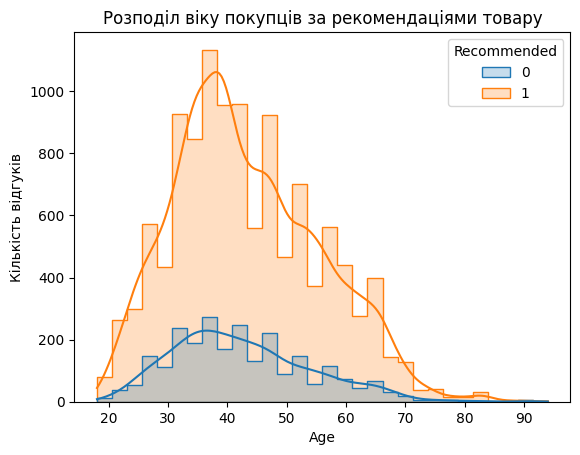

In [13]:
sns.histplot(data=df_review_data, x="Age", hue="Recommended", bins=30, kde=True, element="step")
plt.title("Розподіл віку покупців за рекомендаціями товару")
plt.ylabel("Кількість відгуків")
plt.show()

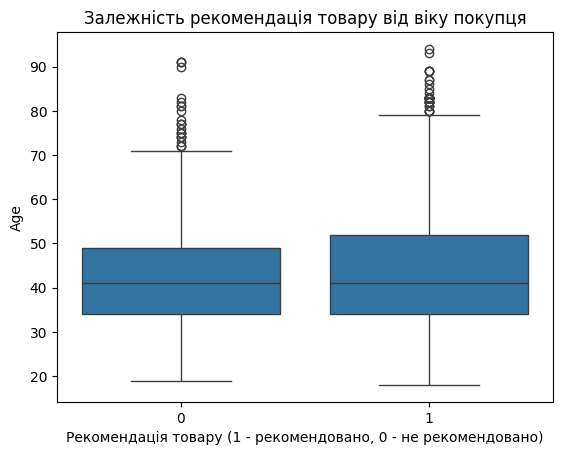

In [14]:
sns.boxplot(data=df_review_data, x="Recommended", y="Age")
plt.title("Залежність рекомендація товару від віку покупця")
plt.xlabel("Рекомендація товару (1 - рекомендовано, 0 - не рекомендовано)")
plt.show()

In [15]:
df_review_data['Pos_Feedback_Cnt'].value_counts()

Pos_Feedback_Cnt
0     6752
1     2441
2     1318
3      857
4      557
      ... 
52       1
89       1
59       1
53       1
48       1
Name: count, Length: 72, dtype: int64

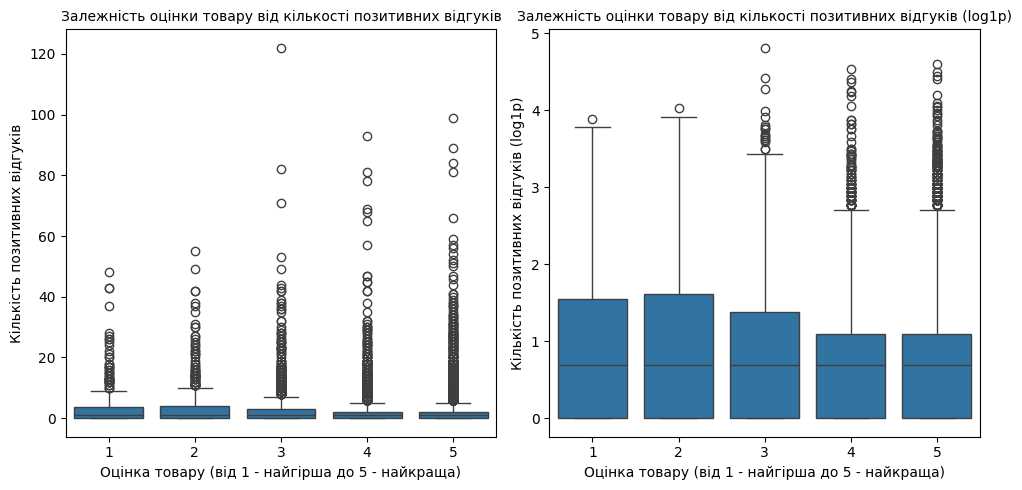

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))

sns.boxplot(data=df_review_data, x="Rating", y="Pos_Feedback_Cnt", ax=axes[0])
axes[0].set_title("Залежність оцінки товару від кількості позитивних відгуків", fontsize=10)
axes[0].set_xlabel("Оцінка товару (від 1 - найгірша до 5 - найкраща)")
axes[0].set_ylabel("Кількість позитивних відгуків")

sns.boxplot(data=df_review_data, x="Rating", y=np.log1p(df_review_data["Pos_Feedback_Cnt"]), ax=axes[1])
axes[1].set_title("Залежність оцінки товару від кількості позитивних відгуків (log1p)", fontsize=10)
axes[1].set_xlabel("Оцінка товару (від 1 - найгірша до 5 - найкраща)")
axes[1].set_ylabel("Кількість позитивних відгуків (log1p)")

plt.tight_layout()
plt.show()

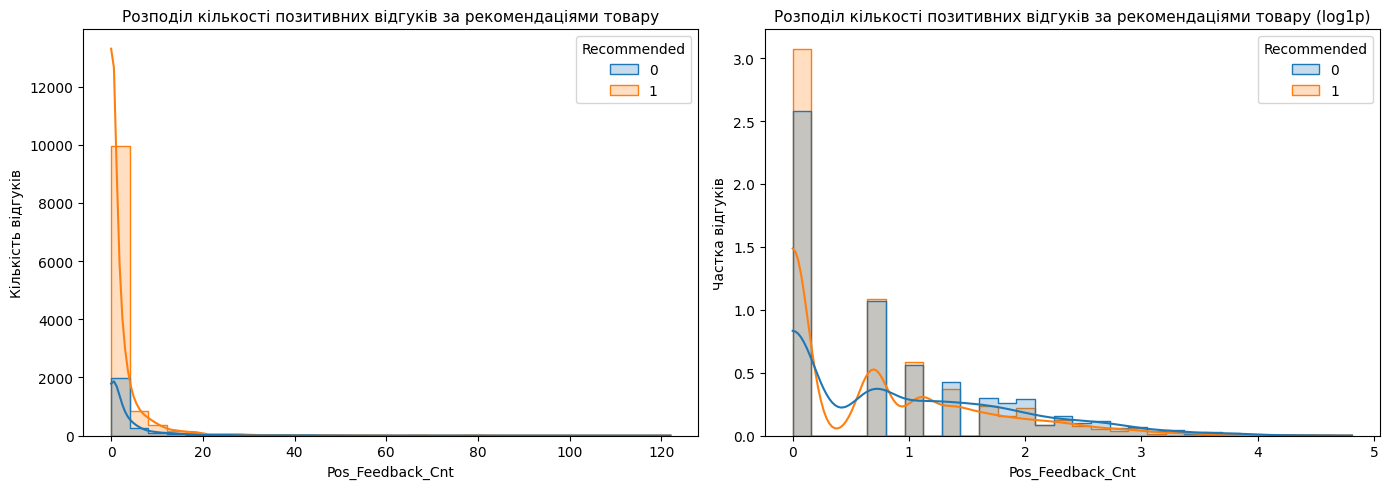

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(data=df_review_data, x="Pos_Feedback_Cnt", hue="Recommended", bins=30, kde=True, element="step", ax=axes[0])
axes[0].set_title("Розподіл кількості позитивних відгуків за рекомендаціями товару", fontsize=11)
axes[0].set_ylabel("Кількість відгуків")

sns.histplot(data=df_review_data, x=np.log1p(df_review_data["Pos_Feedback_Cnt"]), hue="Recommended", bins=30, kde=True, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Розподіл кількості позитивних відгуків за рекомендаціями товару (log1p)", fontsize=11)
axes[1].set_ylabel("Частка відгуків")

plt.tight_layout()
plt.show()

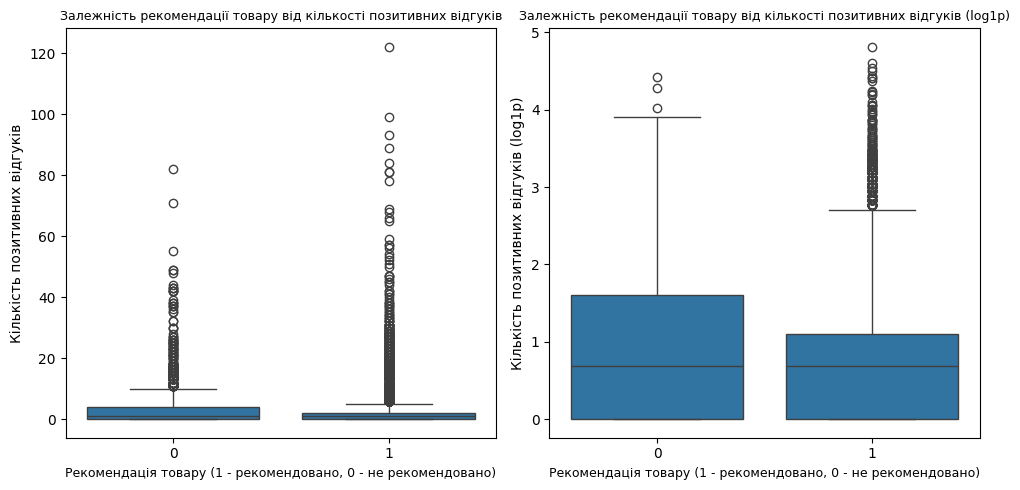

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))

sns.boxplot(data=df_review_data, x="Recommended", y="Pos_Feedback_Cnt", ax=axes[0])
axes[0].set_title("Залежність рекомендації товару від кількості позитивних відгуків", fontsize=9)
axes[0].set_xlabel("Рекомендація товару (1 - рекомендовано, 0 - не рекомендовано)", fontsize=9)
axes[0].set_ylabel("Кількість позитивних відгуків")

sns.boxplot(data=df_review_data, x="Recommended", y=np.log1p(df_review_data["Pos_Feedback_Cnt"]), ax=axes[1])
axes[1].set_title("Залежність рекомендації товару від кількості позитивних відгуків (log1p)", fontsize=9)
axes[1].set_xlabel("Рекомендація товару (1 - рекомендовано, 0 - не рекомендовано)", fontsize=9)
axes[1].set_ylabel("Кількість позитивних відгуків (log1p)")

plt.tight_layout()
plt.show()

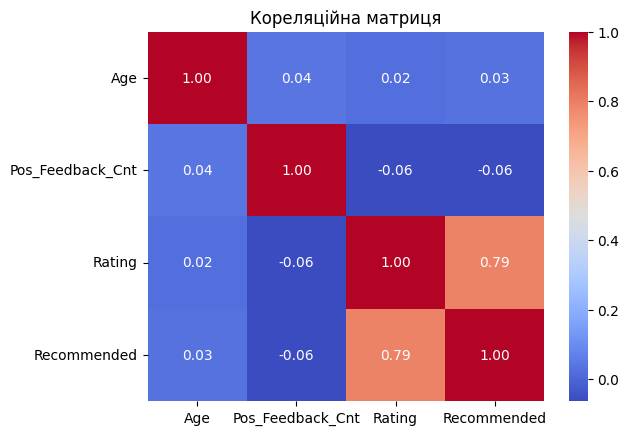

In [19]:
sns.heatmap(df_review_data.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Кореляційна матриця")
plt.yticks(rotation=0)
plt.show()

## Аналіз категоріальних ознак

In [20]:
df_review_data["Division"].value_counts()

Division
General           8352
General Petite    4824
Initmates          904
Name: count, dtype: int64

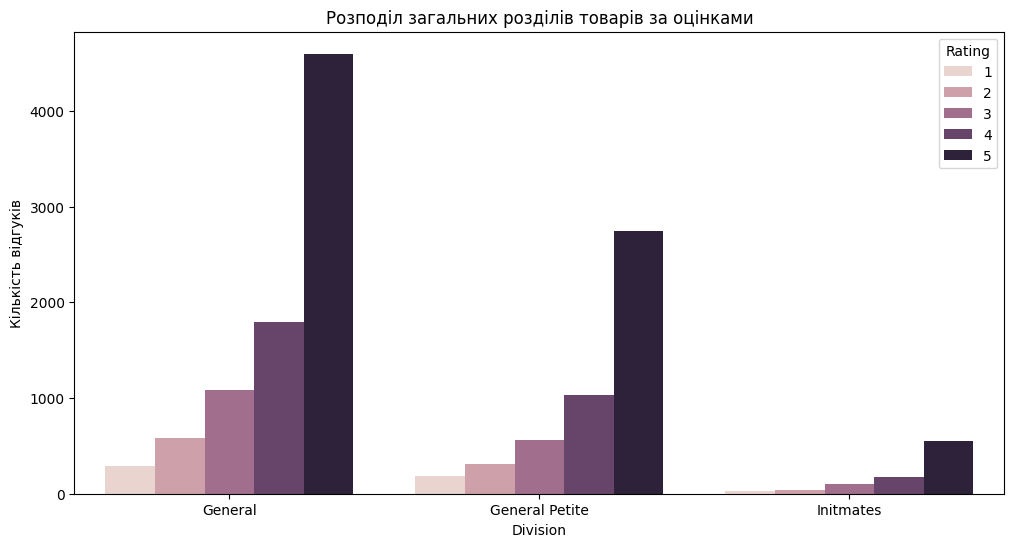

In [21]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_review_data, x="Division", hue="Rating")
plt.title("Розподіл загальних розділів товарів за оцінками")
plt.ylabel("Кількість відгуків")
plt.show()

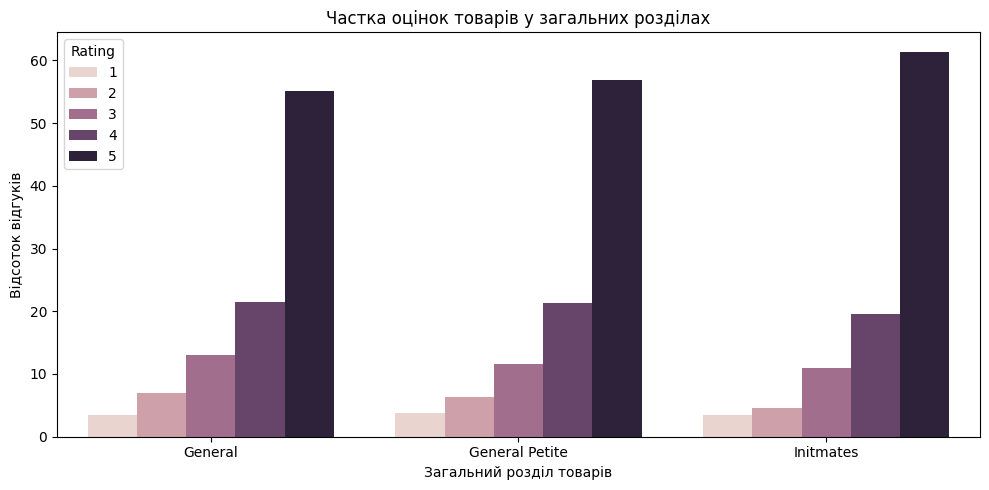

In [22]:
df_percent = (
    df_review_data
    .groupby("Division")["Rating"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percent")
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_percent,
    x="Division",
    y="percent",
    hue="Rating"
)

plt.title("Частка оцінок товарів у загальних розділах")
plt.ylabel("Відсоток відгуків")
plt.xlabel("Загальний розділ товарів")
plt.tight_layout()
plt.show()

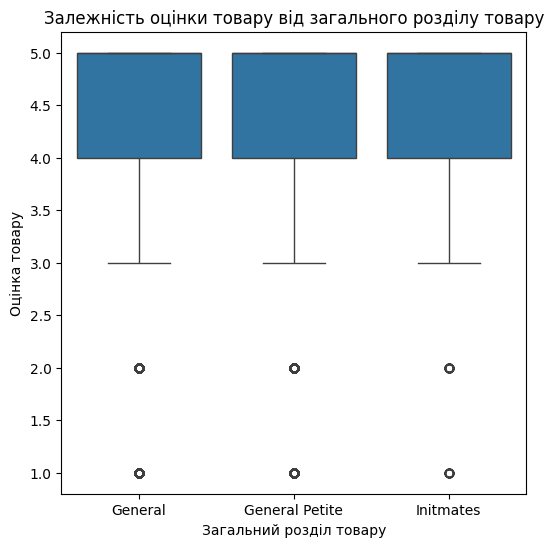

In [23]:
plt.figure(figsize=(6,6))
sns.boxplot(data=df_review_data, x="Division", y="Rating")
plt.title("Залежність оцінки товару від загального розділу товару")
plt.xlabel("Загальний розділ товару")
plt.ylabel("Оцінка товару")
plt.show()

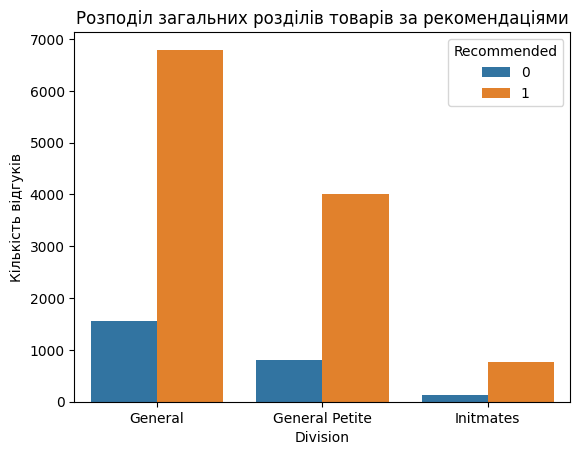

In [24]:
sns.countplot(data=df_review_data, x="Division", hue="Recommended")
plt.title("Розподіл загальних розділів товарів за рекомендаціями")
plt.ylabel("Кількість відгуків")
plt.show()

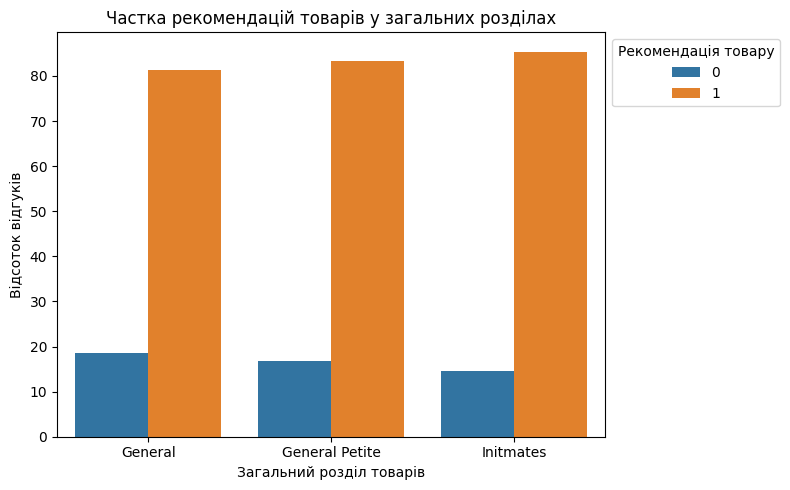

In [25]:
df_percent = (
    df_review_data
    .groupby("Division")["Recommended"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percent")
    .reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_percent,
    x="Division",
    y="percent",
    hue="Recommended"
)

plt.legend(
    title="Рекомендація товару",
    bbox_to_anchor=(1, 1),
    loc="upper left"
)

plt.title("Частка рекомендацій товарів у загальних розділах")
plt.ylabel("Відсоток відгуків")
plt.xlabel("Загальний розділ товарів")
plt.tight_layout()
plt.show()

In [26]:
df_review_data["Department"].value_counts()

Department
Tops        6320
Clothes     3761
Bottoms     2298
Intimate    1039
Coats        589
Trend         73
Name: count, dtype: int64

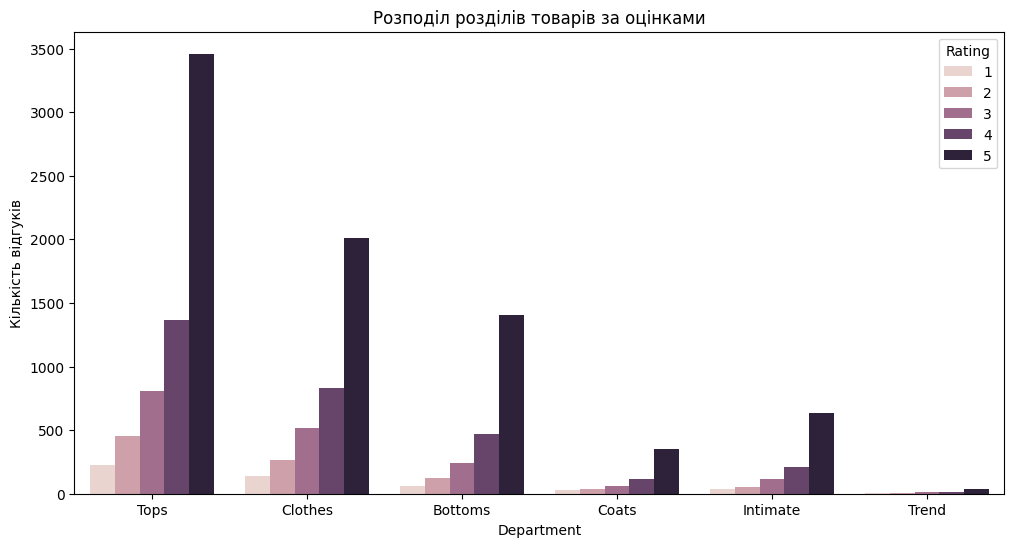

In [27]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_review_data, x="Department", hue="Rating")
plt.title("Розподіл розділів товарів за оцінками")
plt.ylabel("Кількість відгуків")
plt.show()

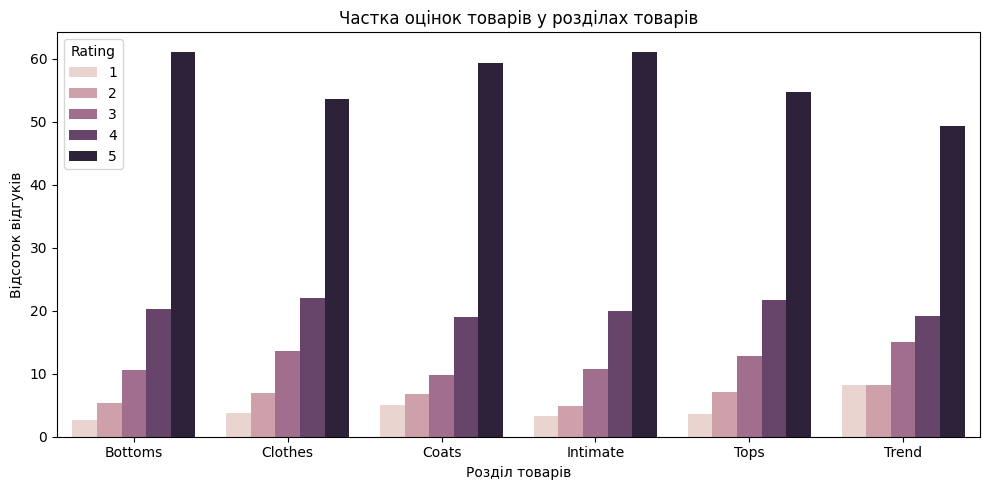

In [28]:
df_percent = (
    df_review_data
    .groupby("Department")["Rating"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percent")
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_percent,
    x="Department",
    y="percent",
    hue="Rating"
)

plt.title("Частка оцінок товарів у розділах товарів")
plt.ylabel("Відсоток відгуків")
plt.xlabel("Розділ товарів")
plt.tight_layout()
plt.show()

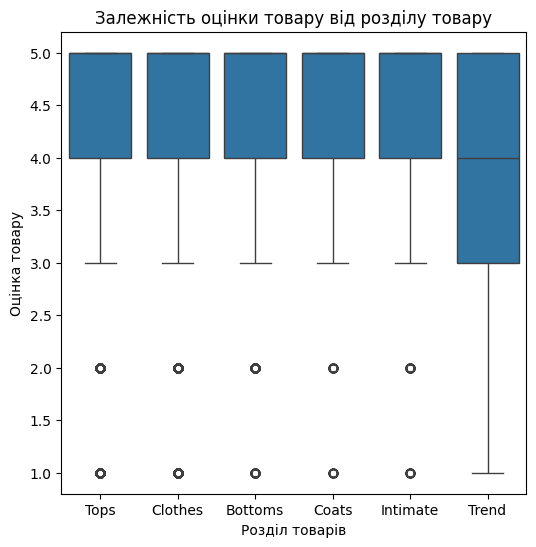

In [29]:
plt.figure(figsize=(6,6))
sns.boxplot(data=df_review_data, x="Department", y="Rating")
plt.title("Залежність оцінки товару від розділу товару")
plt.xlabel("Розділ товарів")
plt.ylabel("Оцінка товару")
plt.show()

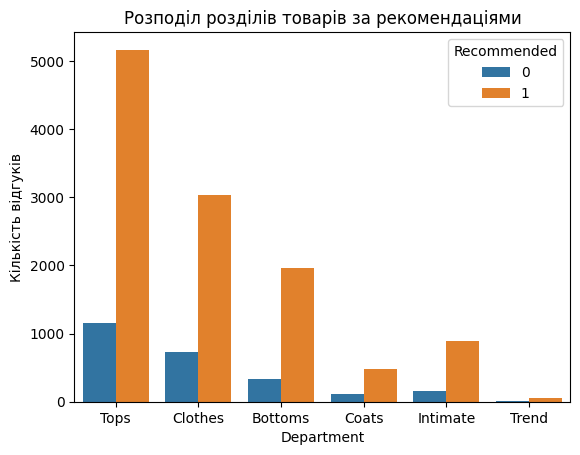

In [30]:
sns.countplot(data=df_review_data, x="Department", hue="Recommended")
plt.title("Розподіл розділів товарів за рекомендаціями")
plt.ylabel("Кількість відгуків")
plt.show()

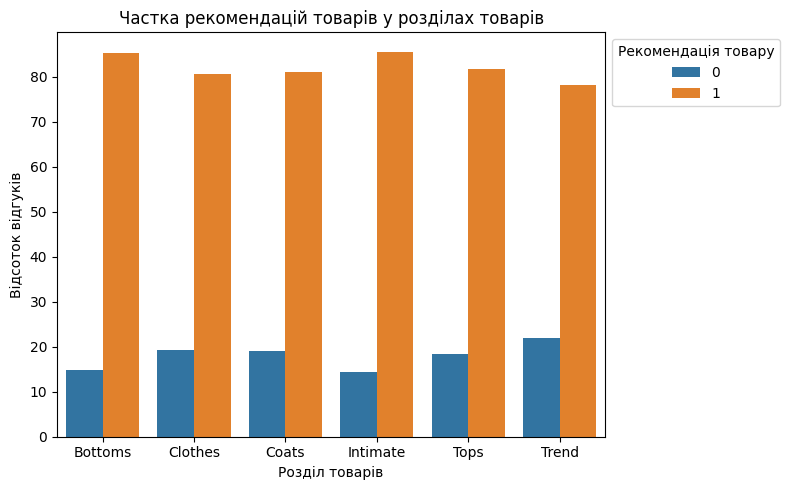

In [31]:
df_percent = (
    df_review_data
    .groupby("Department")["Recommended"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percent")
    .reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_percent,
    x="Department",
    y="percent",
    hue="Recommended"
)

plt.legend(
    title="Рекомендація товару",
    bbox_to_anchor=(1, 1),
    loc="upper left"
)

plt.title("Частка рекомендацій товарів у розділах товарів")
plt.ylabel("Відсоток відгуків")
plt.xlabel("Розділ товарів")
plt.tight_layout()
plt.show()

In [32]:
df_review_data["Product_Category"].value_counts()

Product_Category
Clothes           3761
Knits             2949
Blouses           1822
Sweaters           867
Trousers           829
Jeans              702
Fine gauge         682
Skirts             579
Lounge             419
Coats              404
Swim               212
Shorts             186
Outerwear          185
Sleep              136
Legwear            100
Intimates           90
Layering            81
Trend               73
Casual bottoms       2
Chemises             1
Name: count, dtype: int64

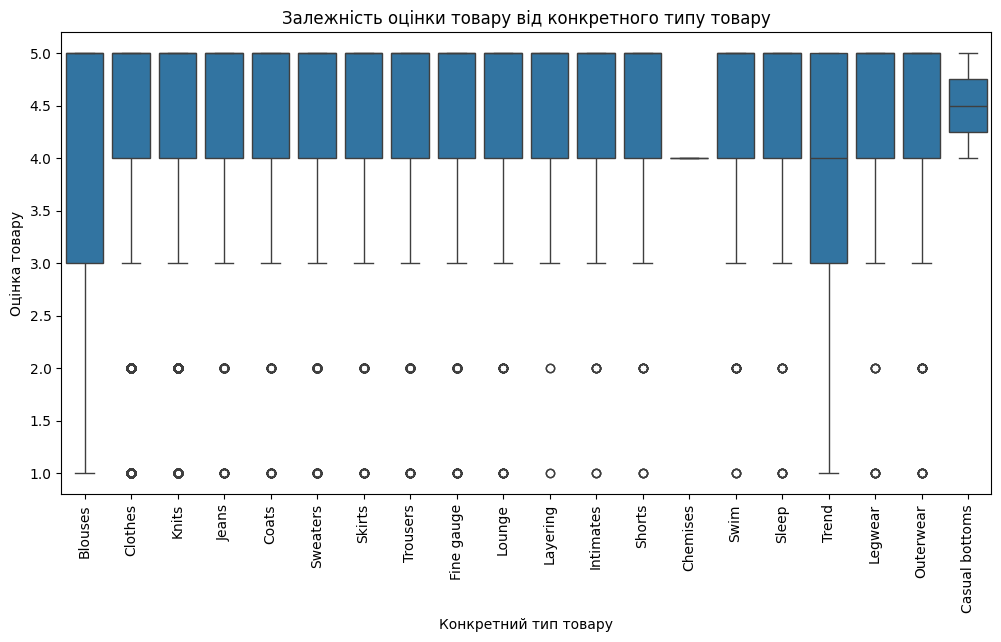

In [33]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_review_data, x="Product_Category", y="Rating")
plt.title("Залежність оцінки товару від конкретного типу товару")
plt.xlabel("Конкретний тип товару")
plt.ylabel("Оцінка товару")
plt.xticks(rotation=90)
plt.show()

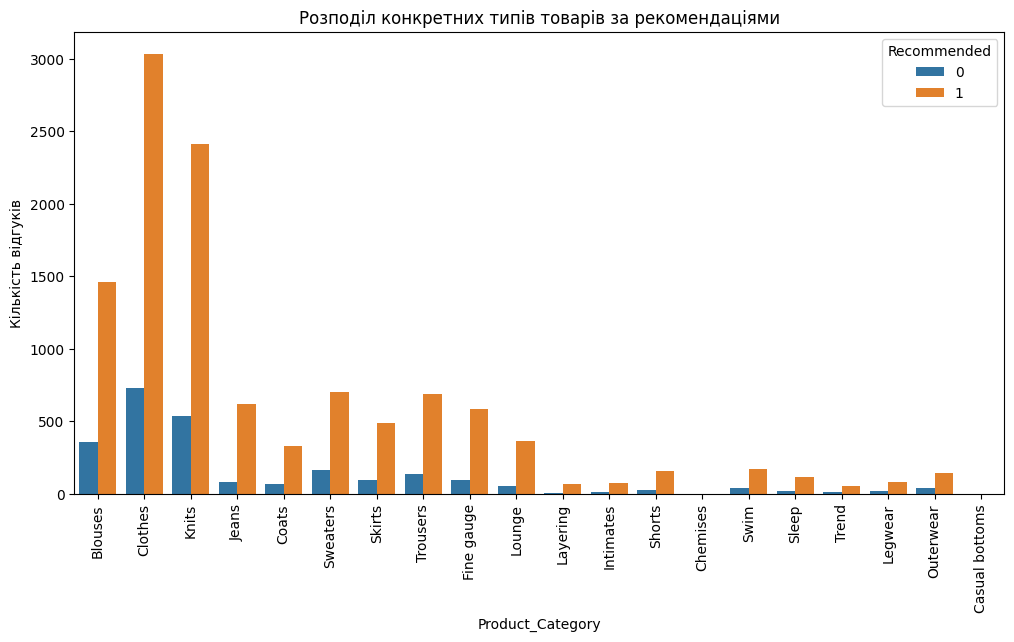

In [34]:
plt.figure(figsize=(12,6))
sns.countplot(data=df_review_data, x="Product_Category", hue="Recommended")
plt.title("Розподіл конкретних типів товарів за рекомендаціями")
plt.ylabel("Кількість відгуків")
plt.xticks(rotation=90)
plt.show()

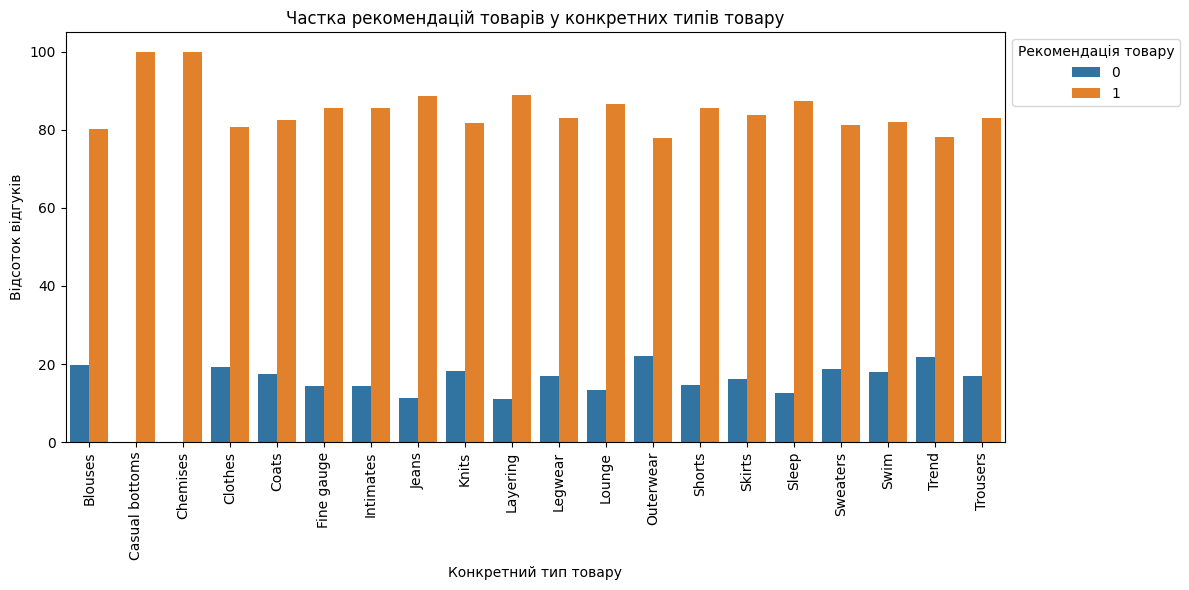

In [35]:
df_percent = (
    df_review_data
    .groupby("Product_Category")["Recommended"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percent")
    .reset_index()
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_percent,
    x="Product_Category",
    y="percent",
    hue="Recommended"
)

plt.legend(
    title="Рекомендація товару",
    bbox_to_anchor=(1, 1),
    loc="upper left"
)

plt.title("Частка рекомендацій товарів у конкретних типів товару")
plt.ylabel("Відсоток відгуків")
plt.xlabel("Конкретний тип товару")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Аналіз текстових ознак

Перевірка пропусків:

In [36]:
text_cols = ["Review_Title", "Review"]
df_review_data[text_cols].isna().sum()

Review_Title    2359
Review           503
dtype: int64

In [37]:
df_review_data[text_cols] = df_review_data[text_cols].fillna("")

Об'єднання заголовка і тексту відгуків:

In [38]:
df_review_data["full_review"] = df_review_data["Review_Title"] + " " +df_review_data["Review"]

Кількість символів і слів:

In [39]:
df_review_data["review_len_chars"] = df_review_data["full_review"].str.len()
df_review_data["review_len_words"] = df_review_data["full_review"].str.split().apply(len)

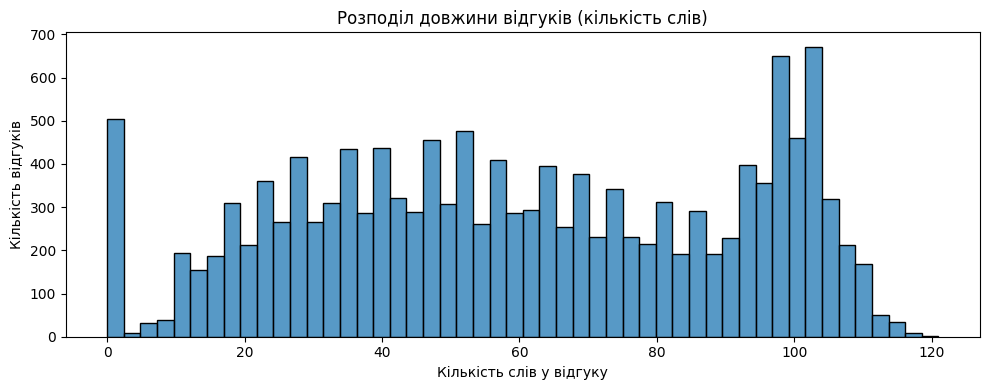

In [40]:
plt.figure(figsize=(10,4))
sns.histplot(data=df_review_data, x="review_len_words", bins=50)
plt.title("Розподіл довжини відгуків (кількість слів)")
plt.xlabel("Кількість слів у відгуку")
plt.ylabel("Кількість відгуків")
plt.tight_layout()
plt.show()

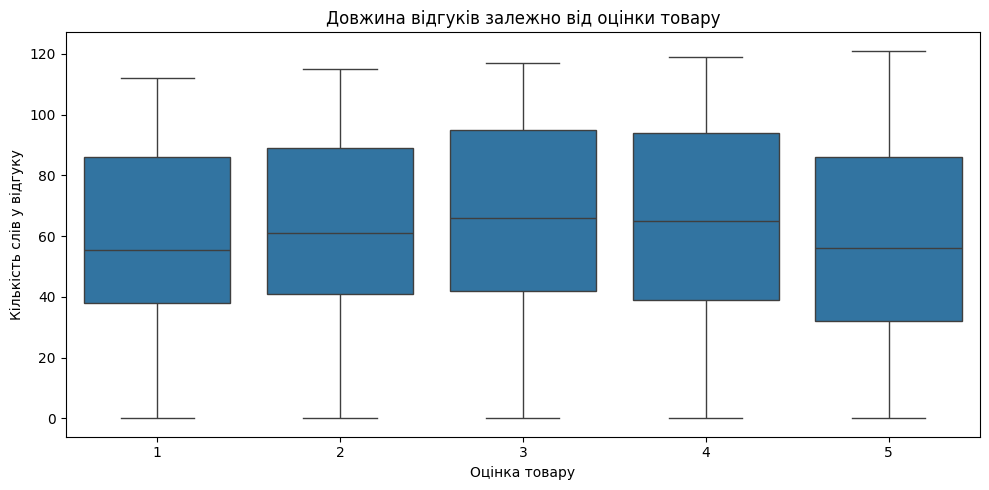

In [41]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_review_data, x="Rating", y="review_len_words")
plt.title("Довжина відгуків залежно від оцінки товару")
plt.xlabel("Оцінка товару")
plt.ylabel("Кількість слів у відгуку")
plt.tight_layout()
plt.show()

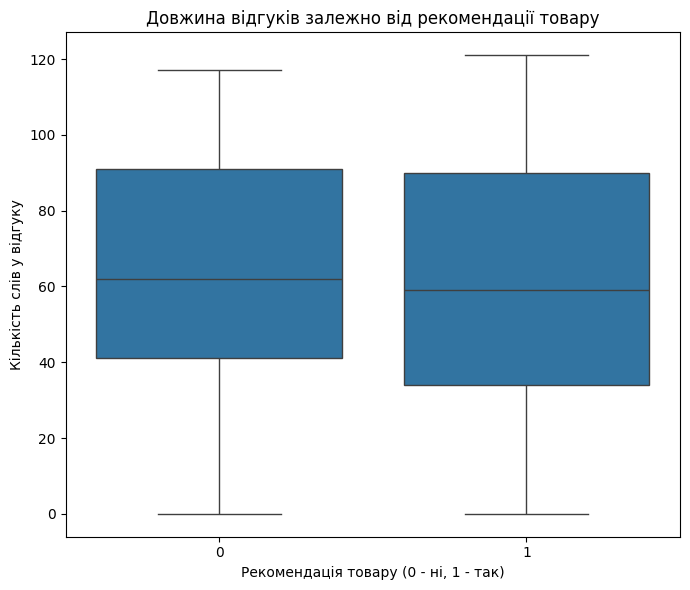

In [42]:
plt.figure(figsize=(7,6))
sns.boxplot(data=df_review_data, x="Recommended", y="review_len_words")
plt.title("Довжина відгуків залежно від рекомендації товару")
plt.xlabel("Рекомендація товару (0 - ні, 1 - так)")
plt.ylabel("Кількість слів у відгуку")
plt.tight_layout()
plt.show()

Очищення тексту:

In [43]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    return text

df_review_data["review_clean"] = df_review_data["full_review"].apply(clean_text)

Частотний аналіз слів:

In [44]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20
)

X = vectorizer.fit_transform(df_review_data["review_clean"])
word_freq = X.sum(axis=0).A1

freq_df = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "count": word_freq
}).sort_values("count", ascending=False)

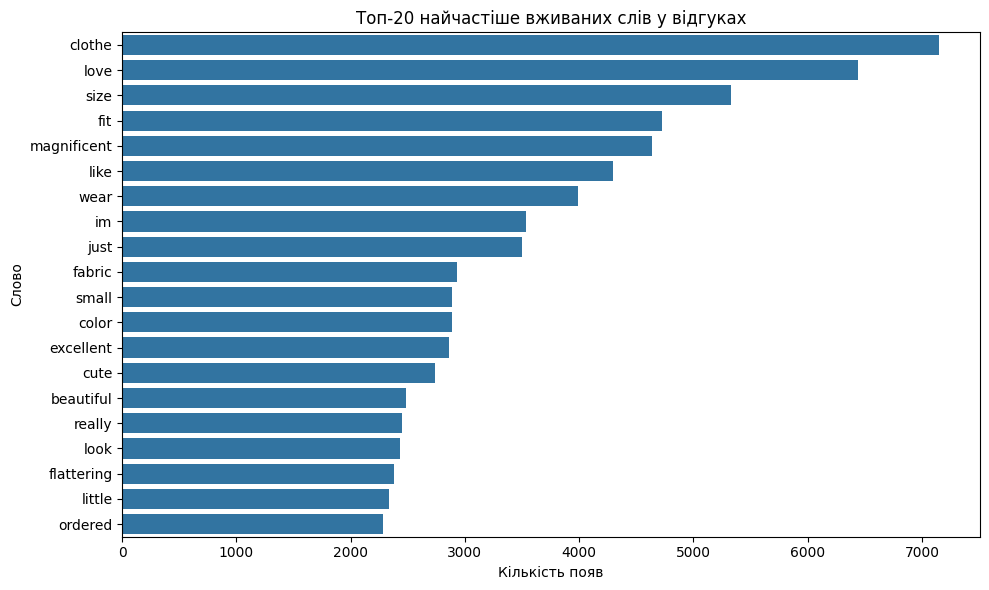

In [45]:
plt.figure(figsize=(10,6))
sns.barplot(data=freq_df, x="count", y="word")
plt.title("Топ-20 найчастіше вживаних слів у відгуках")
plt.xlabel("Кількість появ")
plt.ylabel("Слово")
plt.tight_layout()
plt.show()

Визначення найчастіших слів для кожного класу Recommended:

In [46]:
def top_words_by_target(df, target_value, n=20):
    text = df[df["Recommended"] == target_value]["review_clean"]

    vec = CountVectorizer(stop_words="english", max_features=n)
    X = vec.fit_transform(text)

    return pd.DataFrame({
        "word": vec.get_feature_names_out(),
        "count": X.sum(axis=0).A1
    }).sort_values("count", ascending=False)

Recommended = 1:

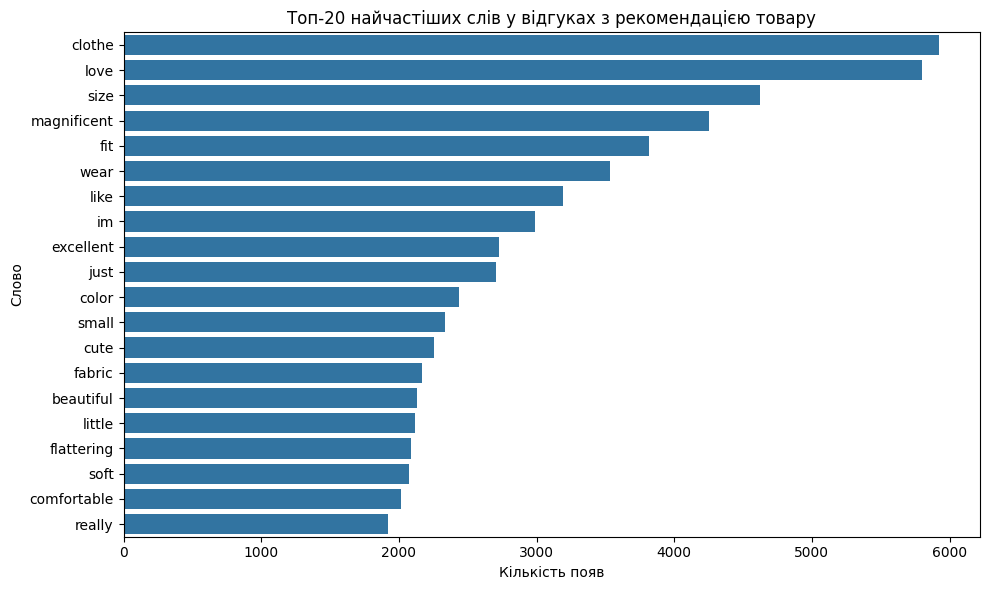

In [47]:
top_rec = top_words_by_target(df_review_data, 1)

plt.figure(figsize=(10,6))
sns.barplot(data=top_rec, x="count", y="word")
plt.title("Топ-20 найчастіших слів у відгуках з рекомендацією товару")
plt.xlabel("Кількість появ")
plt.ylabel("Слово")
plt.tight_layout()
plt.show()

Recommended = 0:

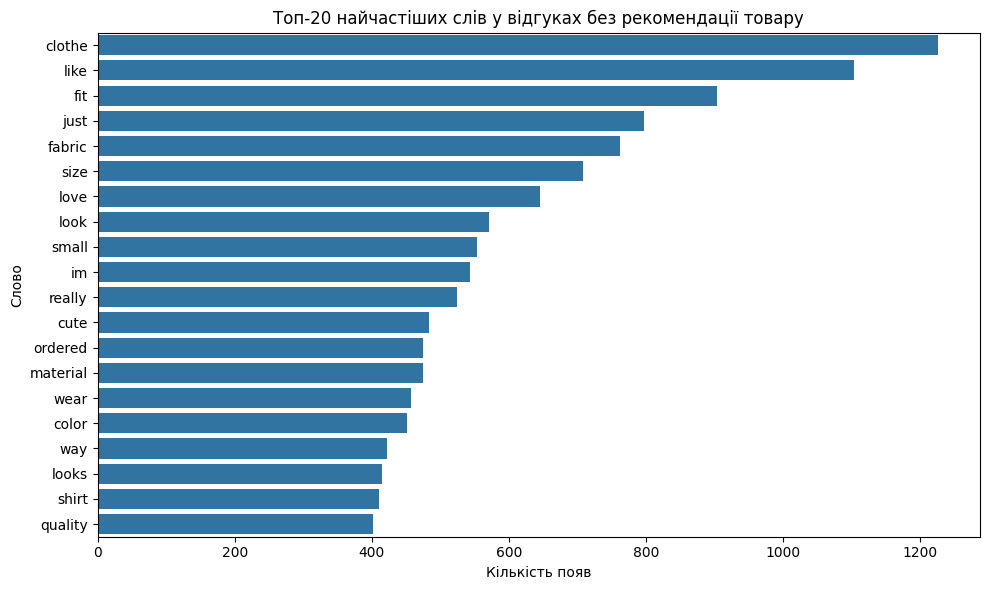

In [48]:
top_not_rec = top_words_by_target(df_review_data, 0)

plt.figure(figsize=(10,6))
sns.barplot(data=top_not_rec, x="count", y="word")
plt.title("Топ-20 найчастіших слів у відгуках без рекомендації товару")
plt.xlabel("Кількість появ")
plt.ylabel("Слово")
plt.tight_layout()
plt.show()

Аналіз інформативності слів у відгуках за допомогою TF-IDF:

In [49]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=20
)

X_tfidf = tfidf.fit_transform(df_review_data["review_clean"])
tfidf_scores = X_tfidf.mean(axis=0).A1

tfidf_df = pd.DataFrame({
    "word": tfidf.get_feature_names_out(),
    "tfidf": tfidf_scores
}).sort_values("tfidf", ascending=False)

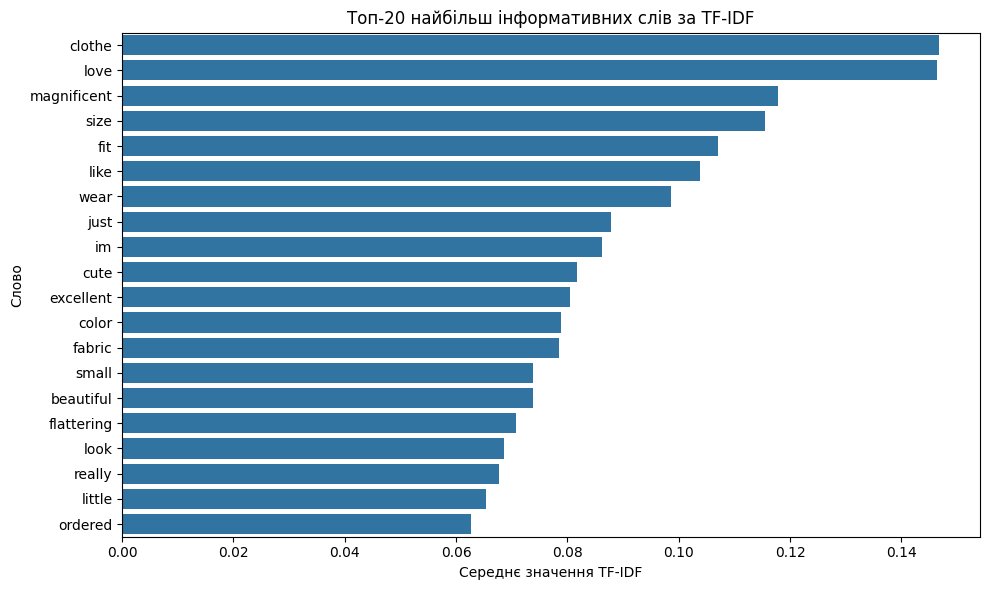

In [50]:
plt.figure(figsize=(10,6))
sns.barplot(data=tfidf_df, x="tfidf", y="word")
plt.title("Топ-20 найбільш інформативних слів за TF-IDF")
plt.xlabel("Середнє значення TF-IDF")
plt.ylabel("Слово")
plt.tight_layout()
plt.show()

## Моделі

Реалізація TF-IDF та DeBERTa:

In [61]:
# BASELINE
BASELINE_PARAMS = {
    "objective": "regression",
    "boosting_type": "gbdt",

    "n_estimators": 1800,   
    "learning_rate": 0.01,

    "num_leaves": 63,
    "max_depth": 8,
    "min_child_samples": 80,

    "feature_fraction": 0.75,  
    "bagging_fraction": 0.75,
    "bagging_freq": 1,

    "lambda_l2": 10.0,

    "random_state": 42,
    "verbosity": -1,
    "n_jobs": -1
}


# Prepare dataframe
def prepare_dataframe(df):
    df = df.copy()

    df["Review_Title"] = df["Review_Title"].fillna("")
    df["Review"] = df["Review"].fillna("")
    df["text"] = df["Review_Title"] + " " + df["Review"]

    cat_cols = ["Division", "Department", "Product_Category"]
    num_cols = ["Age", "Pos_Feedback_Cnt"]

    df["Pos_Feedback_Cnt"] = np.log1p(df["Pos_Feedback_Cnt"])
    
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())

    for col in cat_cols:
        df[col] = df[col].fillna("missing")

        freq = df[col].value_counts(normalize=True)
        df[col] = df[col].map(freq).fillna(0)

    return df, cat_cols, num_cols


# TF-IDF + LightGBM
def train_tfidf_lgbm(df, target_col):
    print(f"\n=== TF-IDF + LightGBM | Target: {target_col} ===")

    df, cat_cols, num_cols = prepare_dataframe(df)

    X_num = csr_matrix(df[num_cols].values)
    X_cat = csr_matrix(df[cat_cols].values)

    tfidf = TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words="english"
    )
    X_text = tfidf.fit_transform(df["text"])

    X = hstack([X_text, X_num, X_cat])
    y = df[target_col].values

    if target_col == "Rating":
        stratify_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
    else:
        stratify_y = y

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(skf.split(X, stratify_y), 1):
        X_train, X_valid = X[train_idx], X[valid_idx]
        y_train, y_valid = y[train_idx], y[valid_idx]

        model = LGBMRegressor(**BASELINE_PARAMS)

        model.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="l2",
            callbacks=[lgb.early_stopping(100, verbose=False)]
        )

        preds = model.predict(X_valid)
        score = spearmanr(y_valid, preds).correlation
        fold_scores.append(score)

        print(f"Fold {fold}: Spearman = {score:.4f}")

    mean_score = np.mean(fold_scores)
    print(f"\nMean CV Spearman: {mean_score:.4f}")

    return mean_score


# DeBERTa embeddings
def get_deberta_embeddings(texts, model_name="microsoft/deberta-v3-base", batch_size=16):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device)
    model.eval()

    embeddings = []

    with torch.no_grad():
        for i in tqdm(range(0, len(texts), batch_size), desc="DeBERTa embeddings"):
            batch = texts[i:i + batch_size]

            tokens = tokenizer(
                batch,
                truncation=True,
                padding=True,
                max_length=256,
                return_tensors="pt"
            ).to(device)

            outputs = model(**tokens)
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(cls_embeddings)

    return np.vstack(embeddings)


# DeBERTa + LightGBM
def train_deberta_lgbm(df, target_col):
    print(f"\n=== DeBERTa + LightGBM | Target: {target_col} ===")

    df, cat_cols, num_cols = prepare_dataframe(df)

    X_num = df[num_cols].values
    X_cat = df[cat_cols].values

    if os.path.exists("deberta_train_embeds.npy"):
        X_text = np.load("deberta_train_embeds.npy")
    else:
        X_text = get_deberta_embeddings(df["text"].tolist())
        np.save("deberta_train_embeds.npy", X_text)

    X = np.hstack([X_text, X_num, X_cat])
    y = df[target_col].values

    if target_col == "Rating":
        stratify_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
    else:
        stratify_y = y

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(skf.split(X, stratify_y), 1):
        X_train, X_valid = X[train_idx], X[valid_idx]
        y_train, y_valid = y[train_idx], y[valid_idx]

        model = LGBMRegressor(**BASELINE_PARAMS)

        model.fit(
            X_train, y_train,
            eval_set=[(X_valid, y_valid)],
            eval_metric="l2",
            callbacks=[lgb.early_stopping(100, verbose=False)]
        )

        preds = model.predict(X_valid)
        score = spearmanr(y_valid, preds).correlation
        fold_scores.append(score)

        print(f"Fold {fold}: Spearman = {score:.4f}")

    mean_score = np.mean(fold_scores)
    print(f"\nMean CV Spearman: {mean_score:.4f}")

    return mean_score

In [62]:
tfidf_rating = train_tfidf_lgbm(df_review_data, "Rating")
deberta_rating = train_deberta_lgbm(df_review_data, "Rating")

tfidf_rec = train_tfidf_lgbm(df_review_data, "Recommended")
deberta_rec = train_deberta_lgbm(df_review_data, "Recommended")

final_tfidf_score = (tfidf_rating + tfidf_rec) / 2
final_deberta_score = (deberta_rating + deberta_rec) / 2

print("\n================ FINAL SCORES ================")
print(f"TF-IDF + LightGBM | Mean Columnwise Spearman: {final_tfidf_score:.4f}")
print(f"DeBERTa + LightGBM | Mean Columnwise Spearman: {final_deberta_score:.4f}")
print("==============================================")


=== TF-IDF + LightGBM | Target: Rating ===


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 1: Spearman = 0.6557


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 2: Spearman = 0.6378


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (30 outputs left out)

Fold 3: Spearman = 0.5806


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fold 4: Spearman = 0.5785
Fold 5: Spearman = 0.5877

Mean CV Spearman: 0.5810

================ FINAL SCORES ================
TF-IDF + LightGBM | Mean Columnwise Spearman: 0.5917
DeBERTa + LightGBM | Mean Columnwise Spearman: 0.6403


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Оптимізація DeBERTa:

In [51]:
# Prepare dataframe
def prepare_dataframe(df):
    df = df.copy()

    df["Review_Title"] = df["Review_Title"].fillna("")
    df["Review"] = df["Review"].fillna("")
    df["text"] = df["Review_Title"] + " " + df["Review"]

    cat_cols = ["Division", "Department", "Product_Category"]
    num_cols = ["Age", "Pos_Feedback_Cnt"]

    df["Pos_Feedback_Cnt"] = np.log1p(df["Pos_Feedback_Cnt"])
    
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())

    for col in cat_cols:
        df[col] = df[col].fillna("missing")

        freq = df[col].value_counts(normalize=True)
        df[col] = df[col].map(freq).fillna(0)

    return df, cat_cols, num_cols


# DeBERTa embeddings
def get_deberta_embeddings(texts, model_name="microsoft/deberta-v3-base", batch_size=16):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device)
    model.eval()

    embeddings = []

    with torch.no_grad():
        for i in tqdm(range(0, len(texts), batch_size), desc="DeBERTa embeddings"):
            batch = texts[i:i + batch_size]

            tokens = tokenizer(
                batch,
                truncation=True,
                padding=True,
                max_length=256,
                return_tensors="pt"
            ).to(device)

            outputs = model(**tokens)
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(cls_embeddings)

    return np.vstack(embeddings)


# DeBERTa + LightGBM + Optuna
def train_deberta_lgbm(df, target_col):
    print(f"\n=== DeBERTa + LightGBM | Target: {target_col} ===")

    df, cat_cols, num_cols = prepare_dataframe(df)

    X_num = df[num_cols].values
    X_cat = df[cat_cols].values

    if os.path.exists("deberta_train_embeds.npy"):
        X_text = np.load("deberta_train_embeds.npy")
    else:
        X_text = get_deberta_embeddings(df["text"].tolist())
        np.save("deberta_train_embeds.npy", X_text)

    X = np.hstack([X_text, X_num, X_cat])
    y = df[target_col].values

    if target_col == "Rating":
        stratify_target = pd.qcut(y, q=5, labels=False, duplicates="drop")
    else:
        stratify_target = y

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    def objective(trial):

        params = {
            "n_estimators": trial.suggest_int("n_estimators", 800, 2500),
            "learning_rate": trial.suggest_float("learning_rate", 0.003, 0.03, log=True),
        
            "num_leaves": trial.suggest_int("num_leaves", 31, 100),
            "max_depth": trial.suggest_int("max_depth", 5, 12),
            "min_child_samples": trial.suggest_int("min_child_samples", 50, 150),

            "lambda_l1": trial.suggest_float("lambda_l1", 0.0, 5.0),
            "lambda_l2": trial.suggest_float("lambda_l2", 0.0, 30.0),
        
            "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 0.9),
            "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 0.9),
            "bagging_freq": trial.suggest_int("bagging_freq", 1, 5),

            "random_state": 42,
            "verbosity": -1,
            "n_jobs": -1
        }
    
        scores = []
    
        for train_idx, valid_idx in skf.split(X, stratify_target):
    
            model = LGBMRegressor(**params)
    
            model.fit(
                X[train_idx], y[train_idx],
                eval_set=[(X[valid_idx], y[valid_idx])],
                eval_metric="l2",
                callbacks=[lgb.early_stopping(100, verbose=False)]
            )
    
            preds = model.predict(X[valid_idx])
            scores.append(
                spearmanr(y[valid_idx], preds).correlation
            )
    
        return np.mean(scores)

    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=20)

    print("\n=== Best Optuna params ===")
    print(study.best_params)
    
    print(f"\nBest mean CV Spearman: {study.best_value:.4f}")

    best_params = {
        **study.best_params,
        "random_state": 42,
        "verbosity": -1,
        "n_jobs": -1
    }

    final_model = LGBMRegressor(**best_params)
    final_model.fit(X, y)

    return final_model, study, study.best_value

In [52]:
deberta_rating_model, deberta_rating_study, deberta_rating = train_deberta_lgbm(df_review_data, "Rating")
deberta_rec_model, deberta_rec_study, deberta_rec = train_deberta_lgbm(df_review_data, "Recommended")

final_deberta_score = (deberta_rating + deberta_rec) / 2

print("\n================ FINAL SCORES ================")
print(f"DeBERTa + LightGBM | Mean Columnwise Spearman: {final_deberta_score:.4f}")
print("==============================================")

[I 2025-12-28 14:39:34,074] A new study created in memory with name: no-name-4cfb8aea-736c-4980-aee4-581d850711f0



=== DeBERTa + LightGBM | Target: Rating ===


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegress


=== Best Optuna params ===
{'n_estimators': 1510, 'learning_rate': 0.015790482109015534, 'num_leaves': 59, 'max_depth': 10, 'min_child_samples': 51, 'lambda_l1': 0.802293203265918, 'lambda_l2': 17.145566118140525, 'feature_fraction': 0.6142266553679474, 'bagging_fraction': 0.6037620739289721, 'bagging_freq': 3}

Best mean CV Spearman: 0.7024


[I 2025-12-28 15:29:06,995] A new study created in memory with name: no-name-d3462aac-fd1e-4fe2-86ac-14c9ef472872



=== DeBERTa + LightGBM | Target: Recommended ===


D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegress


=== Best Optuna params ===
{'n_estimators': 2439, 'learning_rate': 0.02885095967369112, 'num_leaves': 94, 'max_depth': 8, 'min_child_samples': 150, 'lambda_l1': 1.4569584802556155, 'lambda_l2': 29.80824129331246, 'feature_fraction': 0.737082488603554, 'bagging_fraction': 0.7957504171159767, 'bagging_freq': 2}

Best mean CV Spearman: 0.5841

================ FINAL SCORES ================
DeBERTa + LightGBM | Mean Columnwise Spearman: 0.6432


Підготовка тестового датасету до прогнозування:

Завантаження тестового датасету:

In [53]:
file_name = "test.csv"
review_data_test = pd.read_csv(file_name)
review_data_test

,Id,Age,Review_Title,Review,Pos_Feedback_Cnt,Division,Department,Product_Category
0,21403,53,Magnificent clothe!,"In contrast to the other reviewer, i love this...",4,General,Clothes,Clothes
1,22553,51,Shapeless tent,I tried this on in the store and it was huge. ...,2,General,Clothes,Clothes
2,17436,59,Versatile and then some,"I thought this was a fun piece to have, but di...",1,General,Bottoms,Trousers
3,4293,48,So simple but so cute!,I bought the multi-color stripe and it is ador...,1,General,Clothes,Clothes
4,20149,46,Magnificent simple tank,The wide strap style is very flattering. this ...,0,Initmates,Intimate,Layering
...,...,...,...,...,...,...,...,...
9390,13358,24,Love this top!!!!,"This is a sweet, lightweight top that i will w...",11,General Petite,Tops,Knits
9391,12645,32,Magnificent addition to my wardrobe!,"This is a magnificent piece, you can do many t...",0,General Petite,Tops,Knits
9392,7637,35,Channel your inner joanna gaines....,"This anorak is excellention! excellent weight,...",0,General Petite,Coats,Coats
9393,118,37,Awkward fitting,"First, the fabric is beautiful and lovely for ...",0,General,Tops,Blouses


In [54]:
review_data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9395 entries, 0 to 9394
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Id                9395 non-null   int64 
 1   Age               9395 non-null   int64 
 2   Review_Title      7944 non-null   object
 3   Review            9053 non-null   object
 4   Pos_Feedback_Cnt  9395 non-null   int64 
 5   Division          9392 non-null   object
 6   Department        9392 non-null   object
 7   Product_Category  9392 non-null   object
dtypes: int64(3), object(5)
memory usage: 587.3+ KB


In [55]:
review_data_test.isnull().sum()

Id                     0
Age                    0
Review_Title        1451
Review               342
Pos_Feedback_Cnt       0
Division               3
Department             3
Product_Category       3
dtype: int64

Реалізація функції для підготовки submission:

In [74]:
def prepare_submission(test_df, rating_model, recommended_model):

    test_df = test_df.copy()

    test_ids = test_df["Id"].values
    test_df = test_df.drop(columns=["Id"])

    # Rating
    df_rating, cat_cols_rating, num_cols_rating = prepare_dataframe(test_df)

    X_num_rating = df_rating[num_cols_rating].values
    X_cat_rating = df_rating[cat_cols_rating].values
    
    # Text embeddings
    if os.path.exists("deberta_test_embeds.npy"):
        X_text = np.load("deberta_test_embeds.npy")
    else:
        X_text = get_deberta_embeddings(df_rating["text"].tolist())
        np.save("deberta_test_embeds.npy", X_text)
    

    X_rating = np.hstack([X_text, X_num_rating, X_cat_rating])

    rating_preds_raw = rating_model.predict(X_rating)
    
    ranks = rankdata(rating_preds_raw, method="ordinal")
    rating_preds = pd.qcut(ranks, q=5, labels=[1,2,3,4,5]).astype(int)

    # Recommended
    df_rec, cat_cols_rec, num_cols_rec = prepare_dataframe(test_df)

    X_num_rec = df_rec[num_cols_rec].values
    X_cat_rec = df_rec[cat_cols_rec].values

    X_rec = np.hstack([X_text, X_num_rec, X_cat_rec])

    rec_preds_raw = recommended_model.predict(X_rec)
    
    threshold = np.percentile(rec_preds_raw, 20)
    rec_preds = (rec_preds_raw >= threshold).astype(int)
    
    # Submission
    submission = pd.DataFrame({
        "Id": test_ids,
        "Rating": rating_preds,
        "Recommended": rec_preds
    })

    submission.to_csv("submission6.csv", index=False)
    print("submission.csv успішно збережено!")

    return submission

In [75]:
submission = prepare_submission(review_data_test, deberta_rating_model, deberta_rec_model)

D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
D:\Data_Science_Course\Projects\danit_venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


submission.csv успішно збережено!
